# Smoothing splines

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import UnivariateSpline, make_smoothing_spline
from ipywidgets import interact, FloatLogSlider

In [2]:
# Colors shared by all the plots
point_color = '#c1121f'
line_color  = '#1f4e79'
true_color  = '#333333'

With regression splines we have to choose the number and the position of the knots. A smoothing spline avoids it: it puts a knot at every observation and controls the flexibility with a penalty on the roughness of the curve. It is the function that minimizes
$$\sum_i (y_i - f(x_i))^2 + \lambda\int f''(t)^2\,dt.$$
With $\lambda = 0$ it interpolates the data, with $\lambda \to \infty$ it is the least squares line.

## The data

In [3]:
def m(x):
    return np.exp(-x**2)

rng = np.random.default_rng(111)

n = 50
x = np.linspace(-3, 3, n)
Y = m(x) + 0.1*rng.normal(size=n)

x_grid = np.linspace(-3, 3, 1000)

In [4]:
def plot_data(ax, legend=True):
    ax.plot(x_grid, m(x_grid), '--', color=true_color, lw=1.5, label='Regression function')
    ax.plot(x, Y, 'o', color=point_color, markersize=6, markeredgecolor='white', markeredgewidth=0.5,
            label='Observed data')
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_ylim(-0.35, 1.45)
    ax.grid(True, alpha=0.25)
    if legend:
        ax.legend(loc='upper left', frameon=False)

## Splines with UnivariateSpline

`UnivariateSpline` controls the smoothness in another way: it looks for the spline with the fewest knots such that the sum of squared residuals is at most `s`. With `s = 0` it interpolates the data.

In [5]:
spl_1 = UnivariateSpline(x, Y, s=0)
spl_2 = UnivariateSpline(x, Y, s=0.5)
spl_3 = UnivariateSpline(x, Y, s=3)

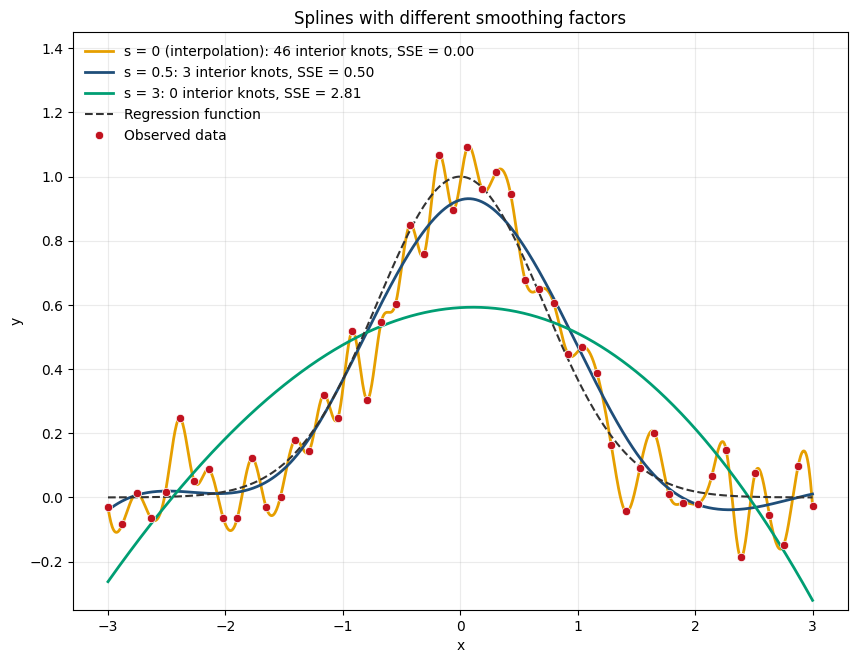

In [6]:
fig, ax = plt.subplots(figsize=(10, 7.5))
splines = [(spl_1, 's = 0 (interpolation)', '#E69F00'), (spl_2, 's = 0.5', line_color), (spl_3, 's = 3', '#009E73')]
for spl, label, color in splines:
    ax.plot(x_grid, spl(x_grid), color=color, lw=2,
            label=f'{label}: {len(spl.get_knots())-2} interior knots, SSE = {spl.get_residual():.2f}')
plot_data(ax)
ax.set_title('Splines with different smoothing factors');

## Smoothing splines with a penalty

`make_smoothing_spline` solves the penalized problem for a given $\lambda$.

In [7]:
def plot_smoothing_spline(ax, lam, legend=True):
    spl = make_smoothing_spline(x, Y, lam=lam)
    ax.plot(x_grid, spl(x_grid), color=line_color, lw=2, label='Smoothing spline')
    plot_data(ax, legend)
    ax.set_title(f'$\\lambda$ = {lam:g}')

Move the slider to change $\lambda$ (this cell needs a running kernel).

In [8]:
def interactive_spline(lam):
    fig, ax = plt.subplots(figsize=(10, 7.5))
    plot_smoothing_spline(ax, lam)
    plt.show()

interact(interactive_spline, lam=FloatLogSlider(value=0.01, base=10, min=-6, max=3, step=0.1, description='lambda'));

interactive(children=(FloatLogSlider(value=0.01, description='lambda', max=3.0, min=-6.0), Output()), _dom_cla…

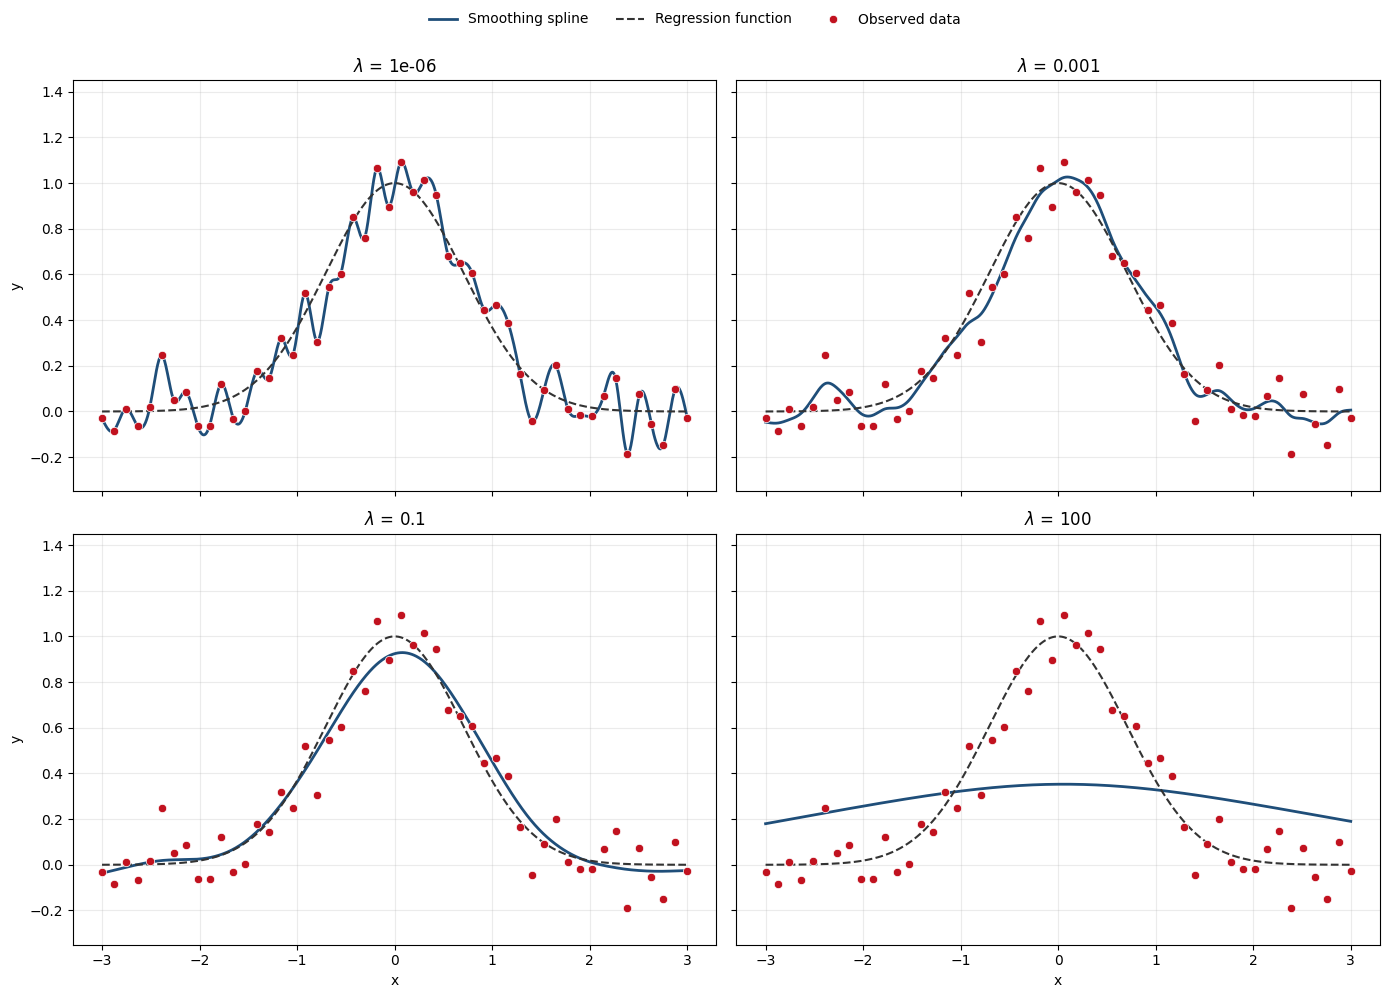

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey=True)
for ax, lam in zip(axes.ravel(), [1e-6, 1e-3, 1e-1, 1e2]):
    plot_smoothing_spline(ax, lam, legend=False)
for ax in axes[0]:
    ax.set_xlabel('')
for ax in axes[:, 1]:
    ax.set_ylabel('')
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.96))

## Effective degrees of freedom

The smoothing spline is linear in the responses, $\hat y = S_\lambda y$. The trace of the smoother matrix $S_\lambda$ plays the role of the number of parameters: it goes from $n$ (interpolation) to 2 (a line). We get the columns of $S_\lambda$ smoothing the columns of the identity matrix.

In [10]:
def smoother_matrix(lam):
    return np.column_stack([make_smoothing_spline(x, e_i, lam=lam)(x) for e_i in np.eye(n)])

lambdas = np.logspace(-6, 3, 60)
df = np.zeros(len(lambdas))
GCV = np.zeros(len(lambdas))

for j, lam in enumerate(lambdas):
    S = smoother_matrix(lam)
    df[j] = np.trace(S)
    GCV[j] = n*sum((Y - S @ Y)**2)/(n-df[j])**2

## Choosing the penalty

The generalized cross-validation criterion,
$$GCV(\lambda) = \frac{n\sum_i (y_i-\hat y_i)^2}{(n-\mathrm{tr}\,S_\lambda)^2},$$
approximates the leave-one-out prediction error without refitting the model.

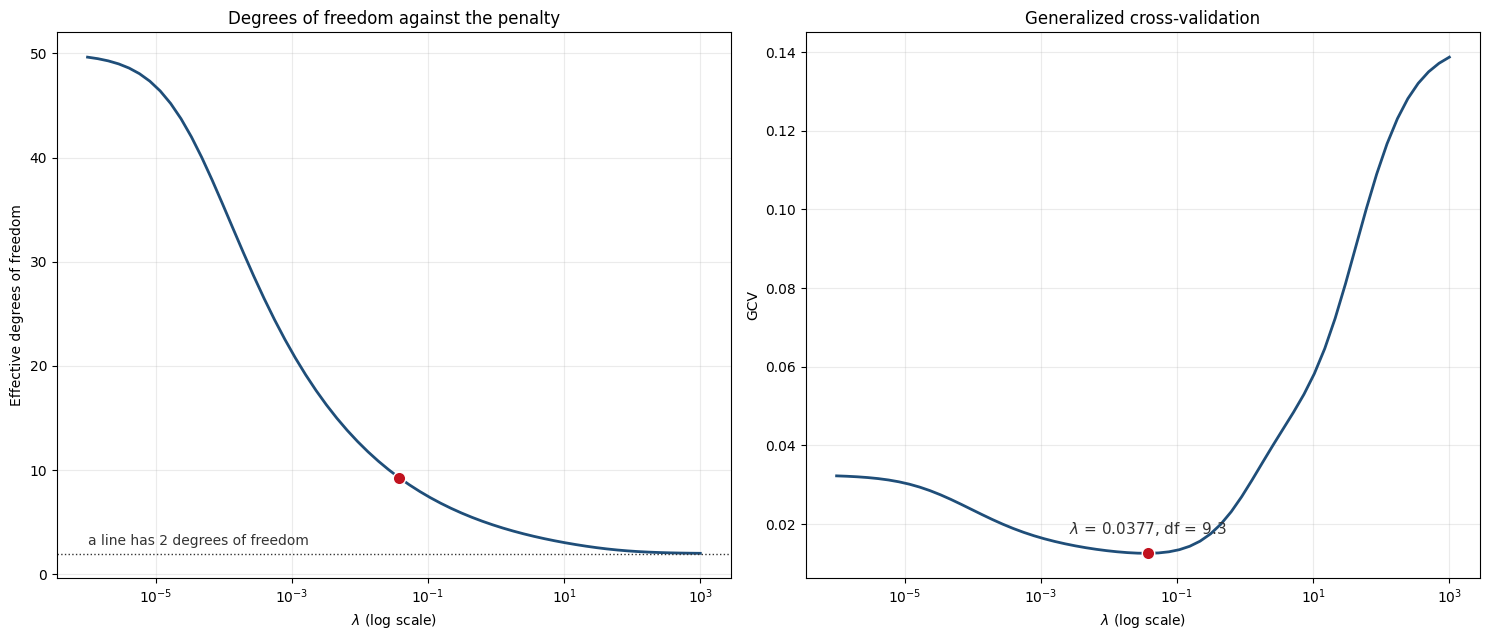

In [11]:
best = np.argmin(GCV)

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))

axes[0].plot(lambdas, df, color=line_color, lw=2)
axes[0].plot(lambdas[best], df[best], 'o', color=point_color, markersize=9, markeredgecolor='white', markeredgewidth=1)
axes[0].axhline(2, ls=':', color=true_color, lw=1)
axes[0].annotate('a line has 2 degrees of freedom', (lambdas[0], 2), xytext=(0, 6), textcoords='offset points',
                 fontsize=10, color=true_color)
axes[0].set_ylabel('Effective degrees of freedom')
axes[0].set_title('Degrees of freedom against the penalty')

axes[1].plot(lambdas, GCV, color=line_color, lw=2)
axes[1].plot(lambdas[best], GCV[best], 'o', color=point_color, markersize=9, markeredgecolor='white', markeredgewidth=1)
axes[1].annotate(f'$\\lambda$ = {lambdas[best]:.3g}, df = {df[best]:.1f}', (lambdas[best], GCV[best]), xytext=(0, 14),
                 textcoords='offset points', ha='center', fontsize=11, color=true_color)
axes[1].set_ylabel('GCV')
axes[1].set_title('Generalized cross-validation')

for ax in axes:
    ax.set_xscale('log')
    ax.set_xlabel(r'$\lambda$ (log scale)')
    ax.grid(True, alpha=0.25)
plt.tight_layout()

If we do not give $\lambda$, `make_smoothing_spline` chooses it by generalized cross-validation.

In [12]:
spl_gcv = make_smoothing_spline(x, Y)
spl_best = make_smoothing_spline(x, Y, lam=lambdas[best])

print('Largest difference between the automatic fit and the one with our lambda:',
      np.max(np.abs(spl_gcv(x_grid) - spl_best(x_grid))))

Largest difference between the automatic fit and the one with our lambda: 0.0021987393128007904


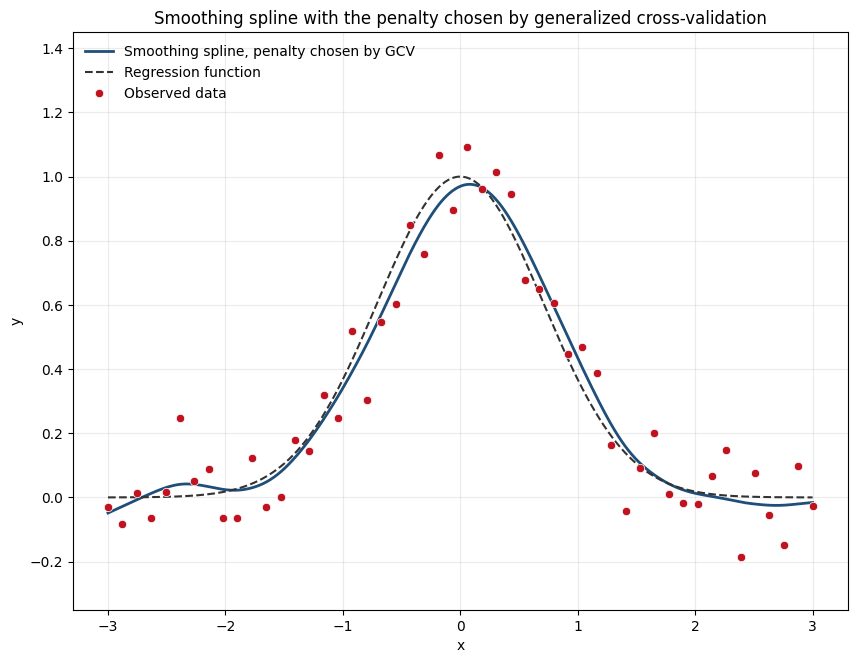

In [13]:
fig, ax = plt.subplots(figsize=(10, 7.5))
ax.plot(x_grid, spl_gcv(x_grid), color=line_color, lw=2, label='Smoothing spline, penalty chosen by GCV')
plot_data(ax)
ax.set_title('Smoothing spline with the penalty chosen by generalized cross-validation');